# Impact-sensitivity classification evaluation

Evaluate completed runs, inspect class-level behaviour, and export reusable tables.

In [43]:
from __future__ import annotations

import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "08_CLASSIFICATION").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Could not locate the repository root")
    PROJECT_ROOT = PROJECT_ROOT.parent

CLASSIFICATION_DIR = PROJECT_ROOT / "08_CLASSIFICATION"
if str(CLASSIFICATION_DIR) not in sys.path:
    sys.path.insert(0, str(CLASSIFICATION_DIR))

from classification_evaluation import (
    CLASSIFICATIONS,
    EMBEDDINGS,
    MODELS,
    SEEDS,
    aggregate_runs,
    completion_table,
    discover_runs,
    export_tables,
    load_predictions,
    normalised_confusion_matrix,
    per_class_metrics,
)

In [44]:
RESULT_DATE = "20260805"
RESULTS_ROOT = PROJECT_ROOT / "07_OUTPUTS" / RESULT_DATE / "IS_classification"
DATASET_PATH = CLASSIFICATION_DIR / "01_DATASETS" / "combined_IS_dataset.csv"
EMBEDDINGS_DIR = CLASSIFICATION_DIR / "02_EMBEDDINGS"
EXPORT_DIR = PROJECT_ROOT / "07_OUTPUTS" / RESULT_DATE / "classification_evaluation"
FIGURES_DIR = EXPORT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASSIFICATION_LABELS = {
    "binary": "Binary",
    "tertiary": "Tertiary",
    "quaternary": "Quaternary",
    "quinary": "Quinary",
}
EMBEDDING_LABELS = {
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "morgan_fps": "ECFP4",
    "maceoff_large": "MACE-OFF",
    "molclr": "MolCLR",
}
MODEL_LABELS = {
    "svc": "SVC",
    "logreg": "Logistic Regression",
    "rf": "Random Forest",
    "lightgbm": "LightGBM",
    "bayes": "Naive Bayes",
    "xgboost": "XGB",
}

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.2)
pd.set_option("display.max_columns", 100)
print(f"Results: {RESULTS_ROOT}")

Results: /home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20260805/IS_classification


In [45]:
def save_figure(fig: plt.Figure, filename: str) -> Path:
    """Save a figure consistently, then display it in the notebook."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {path.relative_to(PROJECT_ROOT)}")
    return path


def apply_display_labels(frame: pd.DataFrame) -> pd.DataFrame:
    """Return a plotting copy with readable category labels."""
    return frame.replace({
        "classification": CLASSIFICATION_LABELS,
        "embedding": EMBEDDING_LABELS,
        "model": MODEL_LABELS,
    })


def draw_confusion_matrix(axis, run_subset: pd.DataFrame, title: str) -> None:
    """Draw one seed-aggregated, row-normalised confusion matrix."""
    if run_subset.empty:
        axis.set_visible(False)
        return

    n_classes = int(run_subset["n_classes"].dropna().iloc[0])
    matrix = normalised_confusion_matrix(run_subset, n_classes)
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        square=True,
        cbar=False,
        ax=axis,
    )
    axis.set(title=title, xlabel="Predicted", ylabel="True")

## 1. Validate data and embeddings

In [46]:
classification_df = pd.read_csv(DATASET_PATH)
missing_targets = set(CLASSIFICATIONS).difference(classification_df.columns)
if missing_targets:
    raise KeyError(f"Missing classification columns: {sorted(missing_targets)}")

embedding_paths = {
    embedding: EMBEDDINGS_DIR / f"{embedding}_embeddings.npy"
    for embedding in EMBEDDINGS
}
embedding_summary = pd.DataFrame([
    {
        "embedding": embedding,
        "rows": matrix.shape[0],
        "dimensions": matrix.shape[1] if matrix.ndim == 2 else np.nan,
        "dtype": str(matrix.dtype),
        "aligned": matrix.shape[0] == len(classification_df),
    }
    for embedding, path in embedding_paths.items()
    for matrix in [np.load(path, mmap_mode="r")]
])
if not embedding_summary["aligned"].all():
    raise ValueError("At least one embedding is not aligned with the dataset")

class_counts = pd.concat(
    [
        classification_df[name].value_counts().sort_index().rename(name)
        for name in CLASSIFICATIONS
    ],
    axis=1,
).T.rename(index=CLASSIFICATION_LABELS)

display(embedding_summary)
display(class_counts.style.format("{:.0f}", na_rep=""))

,embedding,rows,dimensions,dtype,aligned
0,hq_descriptor,980,17,float64,True
1,chemeleon,980,2048,float32,True
2,morgan_fps,980,2048,int64,True
3,maceoff_large,980,448,float64,True
4,molclr,980,512,float64,True


,0,1,2,3,4
Binary,392,588,,,
Tertiary,323,311,346,,
Quaternary,235,257,255,233,
Quinary,179,213,208,308,72


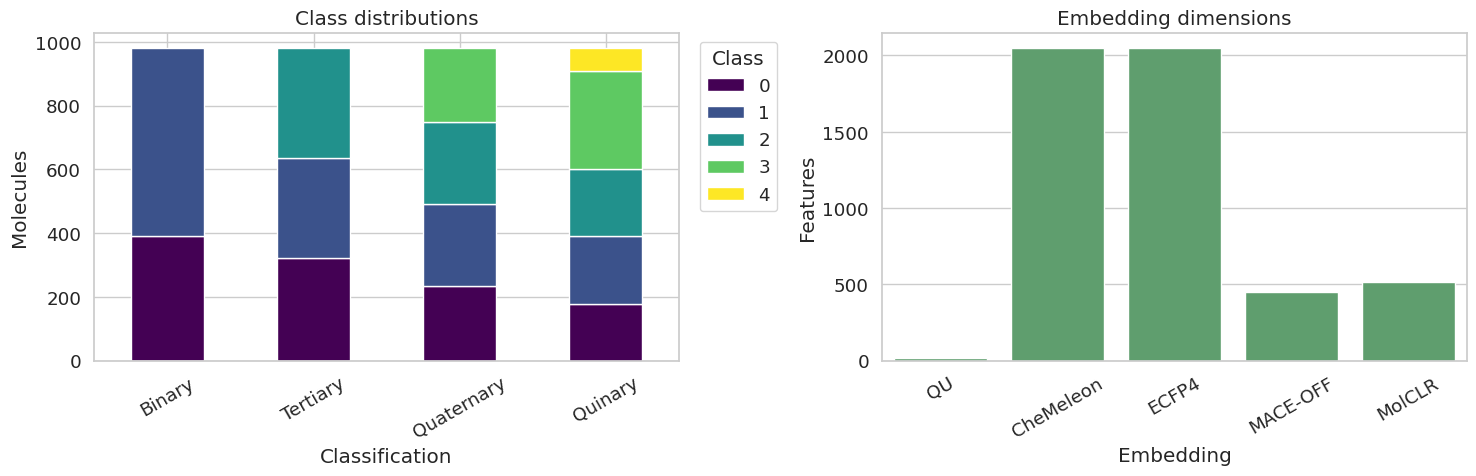

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_data_and_embedding_summary.png


In [47]:
plot_embedding_summary = embedding_summary.replace({"embedding": EMBEDDING_LABELS})
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

class_counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set(title="Class distributions", xlabel="Classification", ylabel="Molecules")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Class", bbox_to_anchor=(1.02, 1))

sns.barplot(
    data=plot_embedding_summary,
    x="embedding",
    y="dimensions",
    order=[EMBEDDING_LABELS[name] for name in EMBEDDINGS],
    color="#55A868",
    ax=axes[1],
)
axes[1].set(title="Embedding dimensions", xlabel="Embedding", ylabel="Features")
axes[1].tick_params(axis="x", rotation=30)

fig.tight_layout()
save_figure(fig, "classification_data_and_embedding_summary.png");

## 2. Discover completed and missing runs

Partial batches are valid; missing combinations are reported and never imputed.

In [48]:
runs, rejected_summaries = discover_runs(RESULTS_ROOT)
completion, missing_runs = completion_table(runs)

print(f"Completed unique runs: {len(runs)} / {len(completion)}")
print(f"Missing runs: {len(missing_runs)}; rejected summaries: {len(rejected_summaries)}")
display(runs.head())
if not rejected_summaries.empty:
    display(rejected_summaries)

Completed unique runs: 600 / 600
Missing runs: 0; rejected summaries: 0


,classification,n_classes,model,embedding,seed,embedding_dim,test_size,cv_splits,n_train,n_test,best_cv_score,best_params,train_accuracy,train_balanced_accuracy,train_f1_macro,train_roc_auc,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,test_roc_auc,roc_auc_error,test_confusion_matrix,test_classification_report,duration_seconds,started_at,finished_at,run_dir,summary_path
0,binary,2,bayes,chemeleon,0,2048,0.2,3,784,196,0.668631,"{""classifier__var_smoothing"": 3.16227766016837...",0.679847,0.709724,0.679821,0.773072,0.704082,0.721643,0.713836,0.721643,0.702968,0.706680,0.778031,None,"[[63, 15], [43, 75]]","{'0': {'precision': 0.5943396226415094, 'recal...",2.004032,2026-08-05T15:03:16.168288,2026-08-05 15:03:18.172320,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...
1,binary,2,bayes,chemeleon,1,2048,0.2,3,784,196,0.688596,"{""classifier__var_smoothing"": 3.16227766016837...",0.686224,0.708172,0.685930,0.767929,0.663265,0.683399,0.678436,0.683399,0.662703,0.665513,0.726749,None,"[[61, 17], [49, 69]]","{'0': {'precision': 0.5545454545454546, 'recal...",2.196612,2026-08-05T15:04:58.534887,2026-08-05 15:05:00.731499,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...
2,binary,2,bayes,chemeleon,2,2048,0.2,3,784,196,0.703699,"{""classifier__var_smoothing"": 1e-06}",0.693878,0.717197,0.693678,0.771795,0.642857,0.664276,0.660714,0.664276,0.642522,0.644755,0.731095,None,"[[60, 18], [52, 66]]","{'0': {'precision': 0.5357142857142857, 'recal...",2.766559,2026-08-05T15:06:15.958849,2026-08-05 15:06:18.725408,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...
3,binary,2,bayes,chemeleon,3,2048,0.2,3,784,196,0.669542,"{""classifier__var_smoothing"": 1e-06}",0.705357,0.732586,0.705334,0.785042,0.658163,0.681334,0.677951,0.681334,0.657941,0.659721,0.720448,None,"[[62, 16], [51, 67]]","{'0': {'precision': 0.5486725663716814, 'recal...",6.053011,2026-08-05T15:08:05.988279,2026-08-05 15:08:12.041290,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...
4,binary,2,bayes,chemeleon,4,2048,0.2,3,784,196,0.673817,"{""classifier__var_smoothing"": 3.16227766016837...",0.668367,0.697506,0.668348,0.762495,0.709184,0.721534,0.712507,0.721534,0.706979,0.712166,0.742992,None,"[[61, 17], [40, 78]]","{'0': {'precision': 0.6039603960396039, 'recal...",16.084775,2026-08-05T15:11:37.835946,2026-08-05 15:11:53.920721,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...


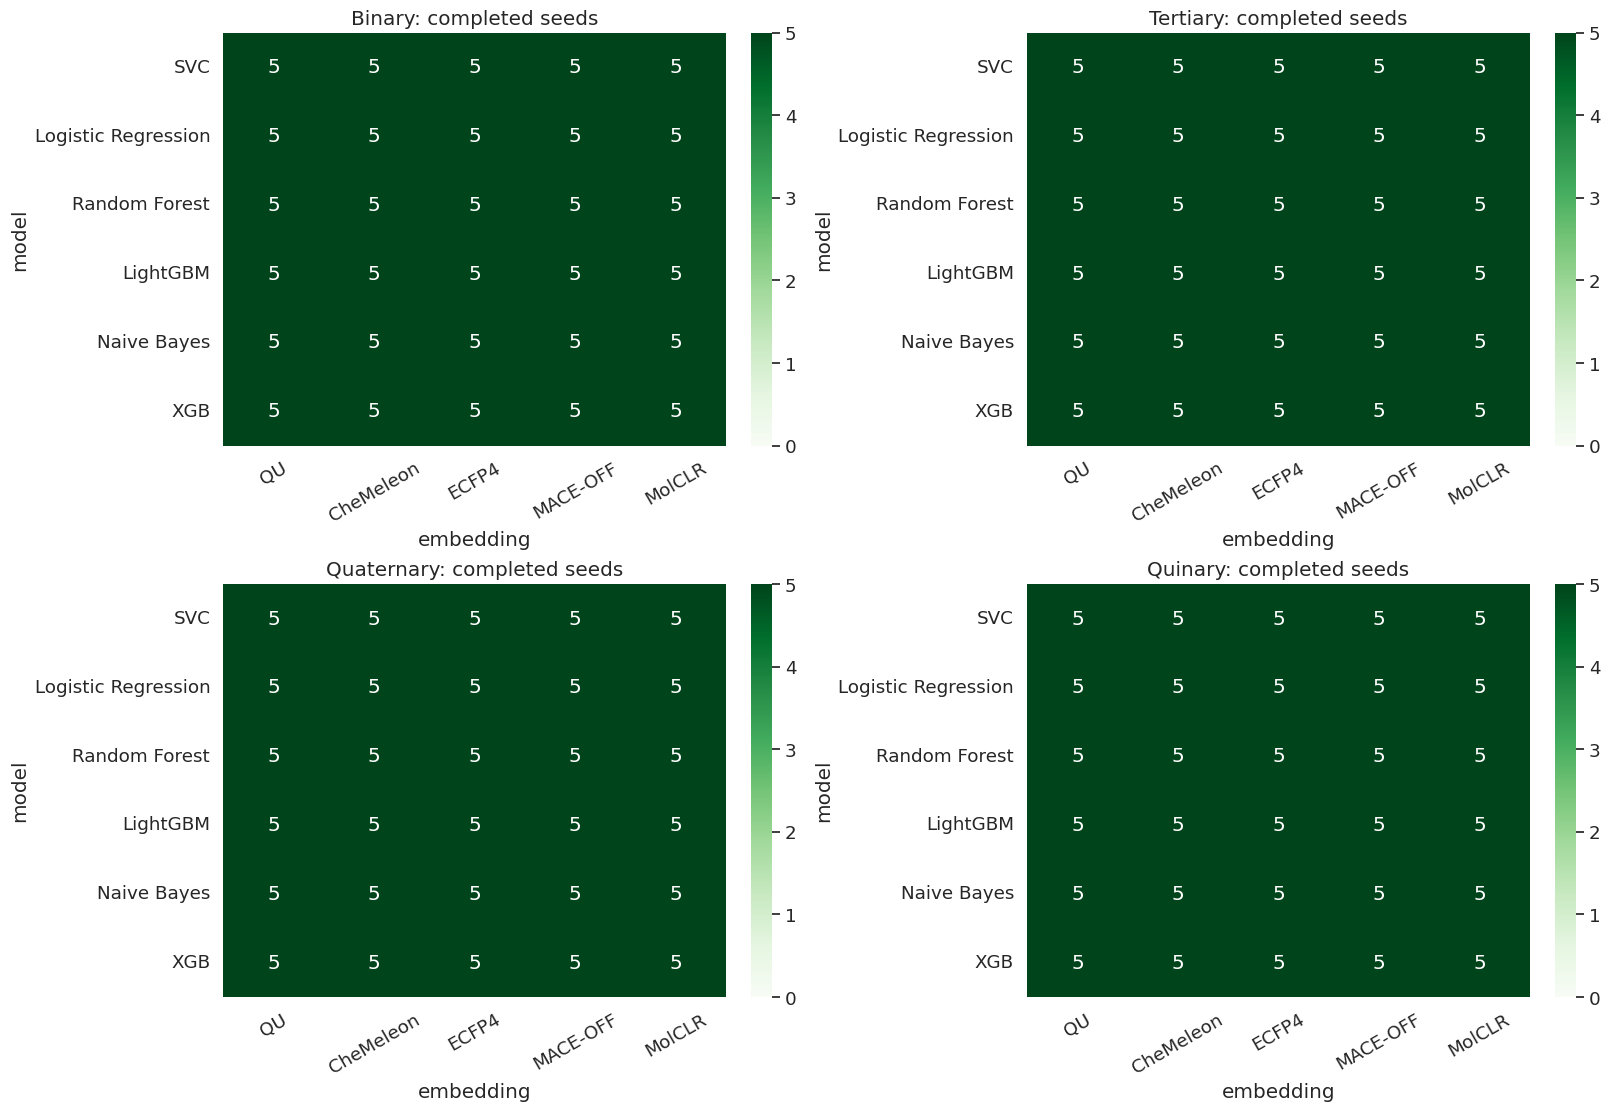

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_run_completion.png


,classification,model,embedding,seed


In [49]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    matrix = (
        completion.loc[completion["classification"] == classification]
        .pivot_table(index="model", columns="embedding", values="completed", aggfunc="sum")
        .reindex(index=MODELS, columns=EMBEDDINGS)
        .rename(index=MODEL_LABELS, columns=EMBEDDING_LABELS)
    )
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".0f",
        cmap="Greens",
        vmin=0,
        vmax=len(SEEDS),
        ax=axis,
    )
    axis.set_title(f"{CLASSIFICATION_LABELS[classification]}: completed seeds")
    axis.tick_params(axis="x", rotation=30)
    axis.tick_params(axis="y", rotation=0)

save_figure(fig, "classification_run_completion.png")
display(missing_runs.head(30))

## 3. Held-out performance across available seeds

In [50]:
aggregate_results = aggregate_runs(runs)
display(aggregate_results.style.format({
    "balanced_accuracy_mean": "{:.3f}",
    "balanced_accuracy_std": "{:.3f}",
    "accuracy_mean": "{:.3f}",
    "f1_macro_mean": "{:.3f}",
    "roc_auc_mean": "{:.3f}",
    "generalisation_gap_mean": "{:.3f}",
    "duration_seconds_mean": "{:.1f}",
}, na_rep="—"))

,classification,model,embedding,seeds_completed,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std,generalisation_gap_mean,duration_seconds_mean
0,binary,lightgbm,chemeleon,5,0.844,0.037,0.855,0.039946,0.847,0.040953,0.924,0.030269,0.156,328.6
1,binary,xgboost,chemeleon,5,0.841,0.038,0.854,0.039619,0.846,0.040883,0.920,0.029283,0.159,257.5
2,binary,rf,maceoff_large,5,0.840,0.023,0.851,0.026363,0.843,0.026115,0.917,0.023911,0.134,148.8
3,binary,lightgbm,maceoff_large,5,0.838,0.018,0.849,0.022122,0.841,0.021447,0.917,0.023409,0.157,153.9
4,binary,rf,chemeleon,5,0.835,0.029,0.851,0.027805,0.841,0.029699,0.920,0.027821,0.148,350.0
5,binary,xgboost,maceoff_large,5,0.831,0.027,0.847,0.027237,0.837,0.028419,0.914,0.024213,0.166,70.4
6,binary,rf,molclr,5,0.821,0.019,0.835,0.020912,0.825,0.020906,0.897,0.011455,0.164,163.3
7,binary,xgboost,molclr,5,0.818,0.022,0.834,0.019294,0.823,0.021061,0.896,0.015232,0.180,85.6
8,binary,logreg,maceoff_large,5,0.813,0.029,0.815,0.026609,0.809,0.027821,0.875,0.027555,0.016,65.7
9,binary,lightgbm,molclr,5,0.813,0.028,0.827,0.024469,0.816,0.026843,0.895,0.017047,0.186,141.7


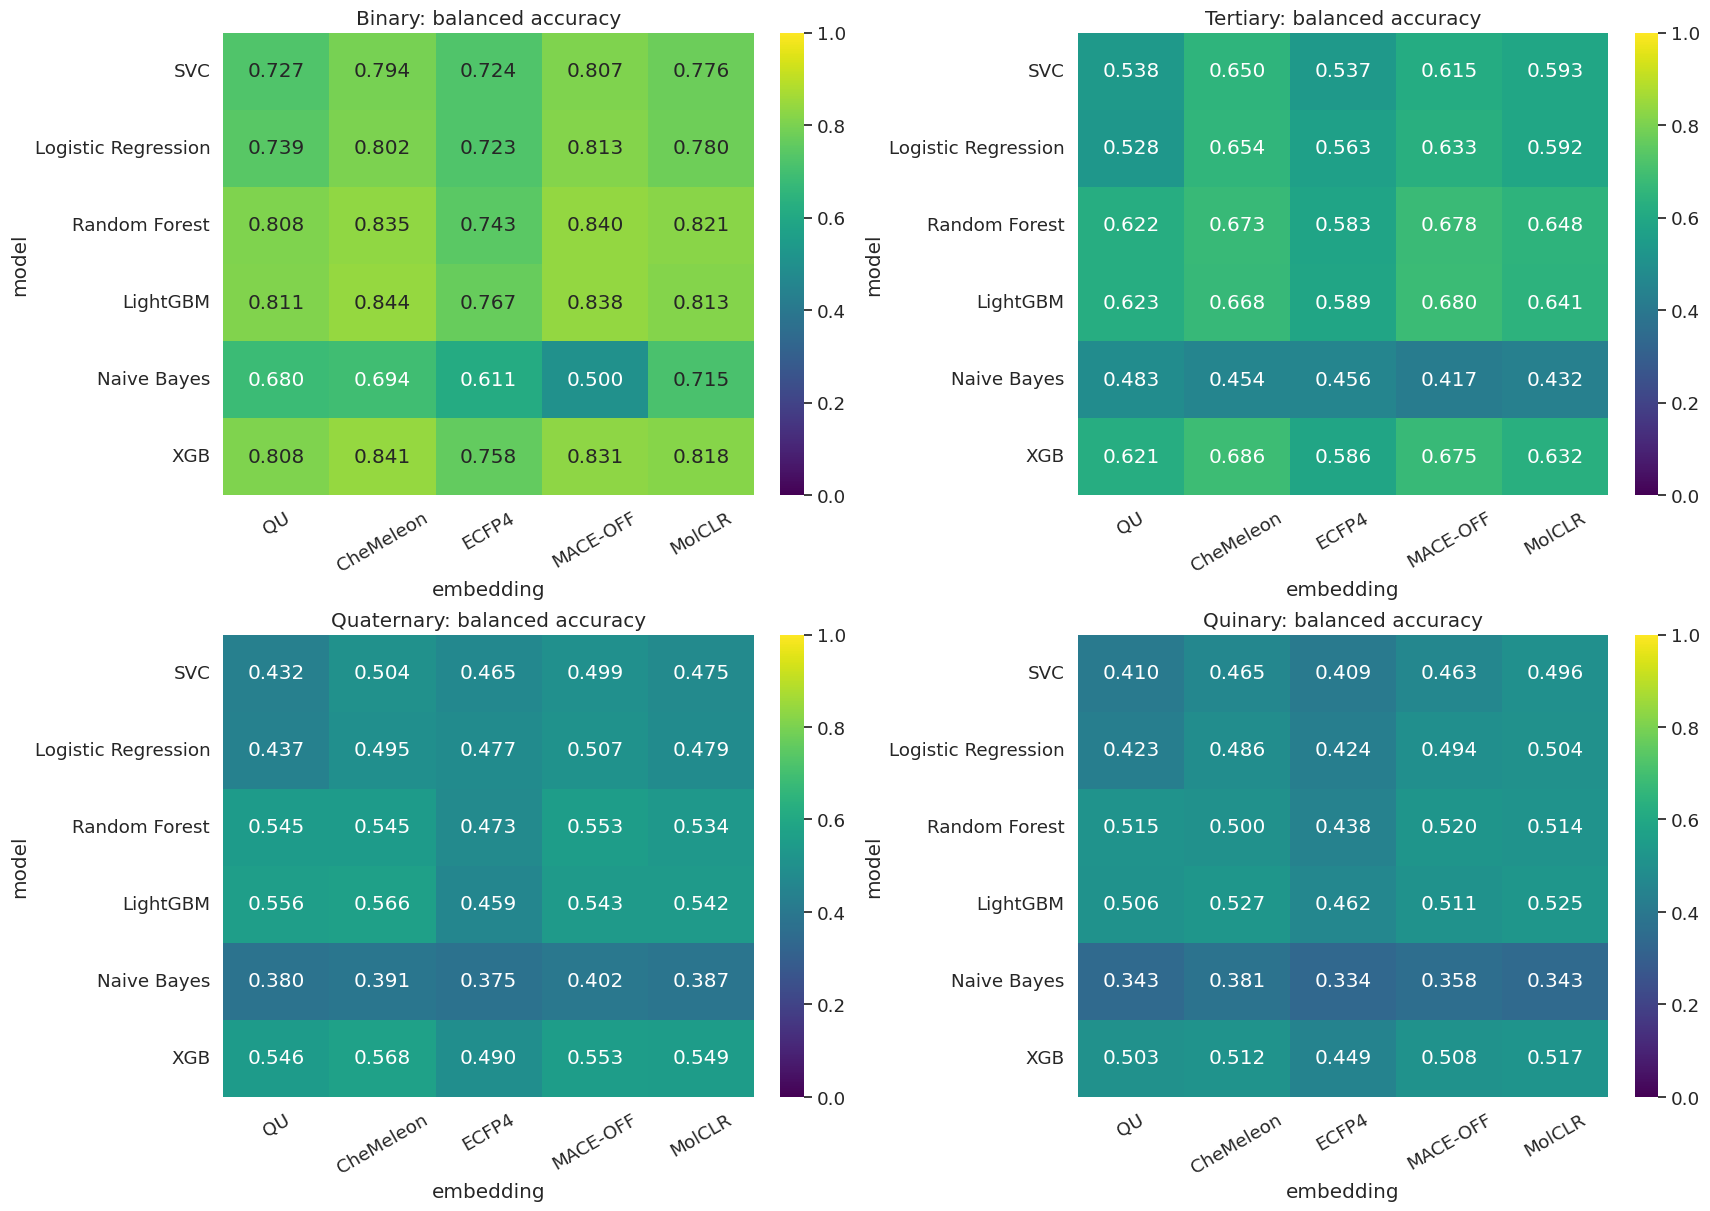

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_balanced_accuracy_heatmaps.png


In [51]:
fig, axes = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    matrix = (
        aggregate_results.loc[aggregate_results["classification"] == classification]
        .pivot(index="model", columns="embedding", values="balanced_accuracy_mean")
        .reindex(index=MODELS, columns=EMBEDDINGS)
        .rename(index=MODEL_LABELS, columns=EMBEDDING_LABELS)
    )
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="viridis",
        vmin=0,
        vmax=1,
        ax=axis,
    )
    axis.set_title(f"{CLASSIFICATION_LABELS[classification]}: balanced accuracy")
    axis.tick_params(axis="x", rotation=30)
    axis.tick_params(axis="y", rotation=0)

save_figure(fig, "classification_balanced_accuracy_heatmaps.png");

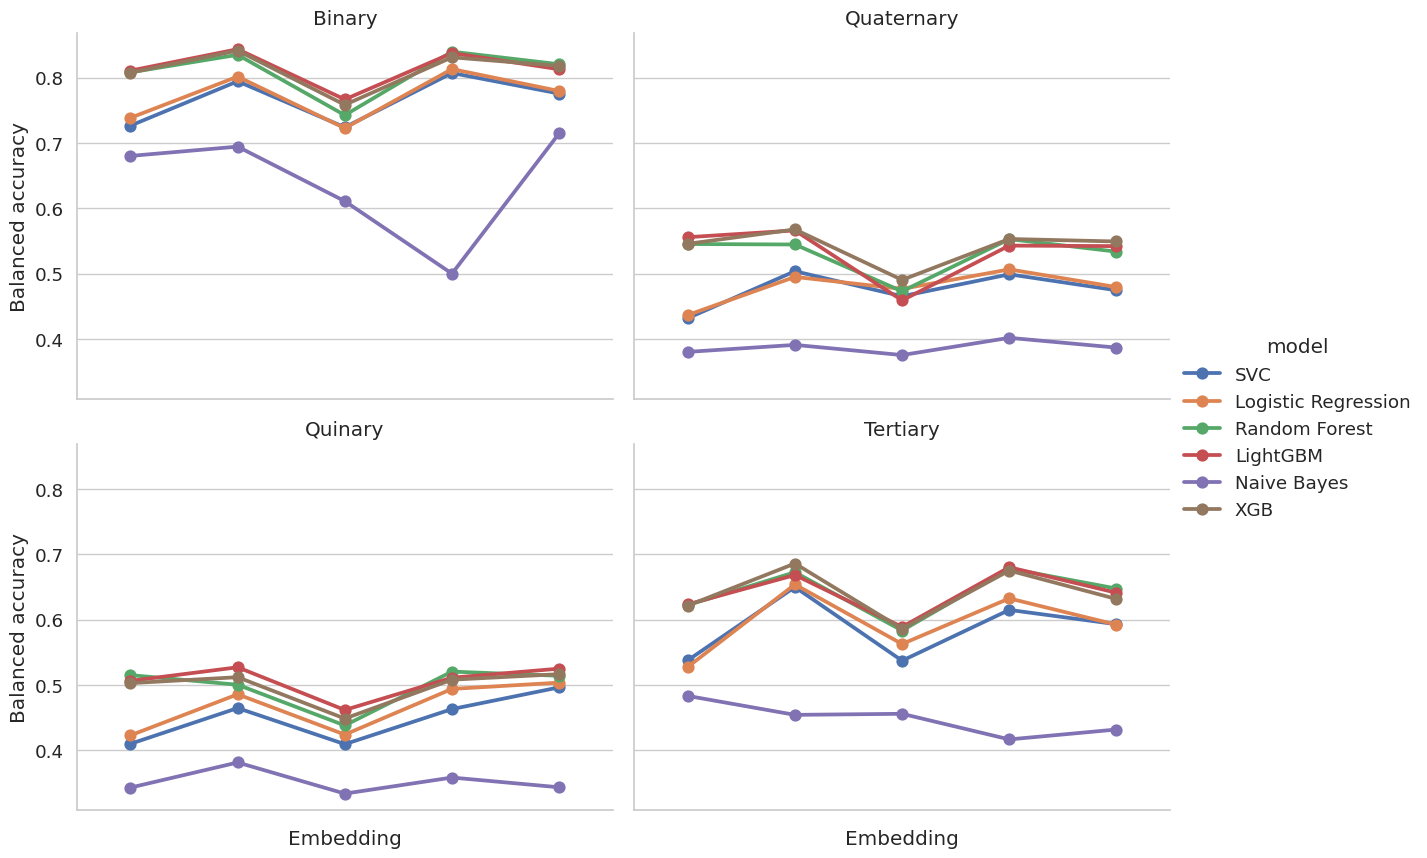

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_balanced_accuracy_by_embedding.png


In [52]:
plot_runs = apply_display_labels(runs)
g = sns.catplot(
    data=plot_runs,
    x="embedding",
    y="test_balanced_accuracy",
    hue="model",
    col="classification",
    col_wrap=2,
    kind="point",
    errorbar=None,
    order=[EMBEDDING_LABELS[name] for name in EMBEDDINGS],
    hue_order=[MODEL_LABELS[name] for name in MODELS],
    height=4.5,
    aspect=1.35,
)
g.set_xticklabels(rotation=30)
g.set_axis_labels("Embedding", "Balanced accuracy")
g.set_titles("{col_name}")
save_figure(g.figure, "classification_balanced_accuracy_by_embedding.png");

## 4. Class-level performance and confusion matrices

In [53]:
class_metrics = per_class_metrics(runs)
class_metric_summary = (
    class_metrics.groupby(
        ["classification", "model", "embedding", "class_label"], as_index=False
    )
    .agg(
        seeds=("seed", "nunique"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        support=("support", "sum"),
    )
)
display(class_metric_summary.sort_values(["classification", "f1"]).head(30))

best_rows = (
    aggregate_results.sort_values("balanced_accuracy_mean", ascending=False)
    .drop_duplicates("classification")
    .set_index("classification")
)

,classification,model,embedding,class_label,seeds,precision,recall,f1,support
4,binary,bayes,maceoff_large,0,5,0.000000,0.000000,0.000000,390
8,binary,bayes,morgan_fps,0,5,0.520016,0.574359,0.545046,390
2,binary,bayes,hq_descriptor,0,5,0.679375,0.528205,0.592537,390
0,binary,bayes,chemeleon,0,5,0.567446,0.787179,0.659215,390
6,binary,bayes,molclr,0,5,0.637867,0.692308,0.662789,390
28,binary,logreg,morgan_fps,0,5,0.678402,0.648718,0.662970,390
48,binary,svc,morgan_fps,0,5,0.669239,0.666667,0.667440,390
42,binary,svc,hq_descriptor,0,5,0.679992,0.661538,0.669488,390
9,binary,bayes,morgan_fps,1,5,0.696827,0.647458,0.670612,590
38,binary,rf,morgan_fps,0,5,0.720187,0.656410,0.685885,390


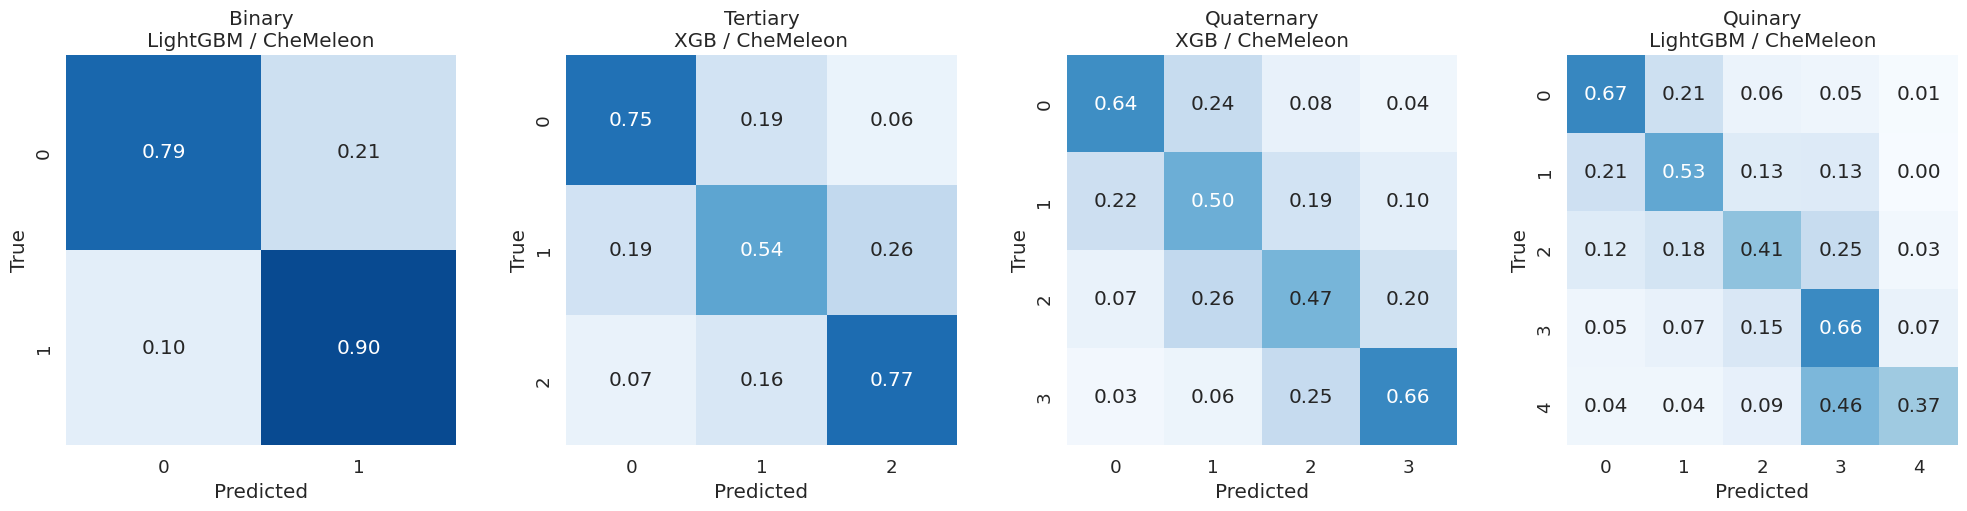

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_best_model_confusion_matrices.png


In [54]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for axis, classification in zip(axes, CLASSIFICATIONS):
    if classification not in best_rows.index:
        axis.set_visible(False)
        continue

    best = best_rows.loc[classification]
    subset = runs.loc[
        (runs["classification"] == classification)
        & (runs["model"] == best["model"])
        & (runs["embedding"] == best["embedding"])
    ]
    title = (
        f"{CLASSIFICATION_LABELS[classification]}\n"
        f"{MODEL_LABELS[best['model']]} / {EMBEDDING_LABELS[best['embedding']]}"
    )
    draw_confusion_matrix(axis, subset, title)

save_figure(fig, "classification_best_model_confusion_matrices.png");

### XGBoost comparison: QU and CheMeleon

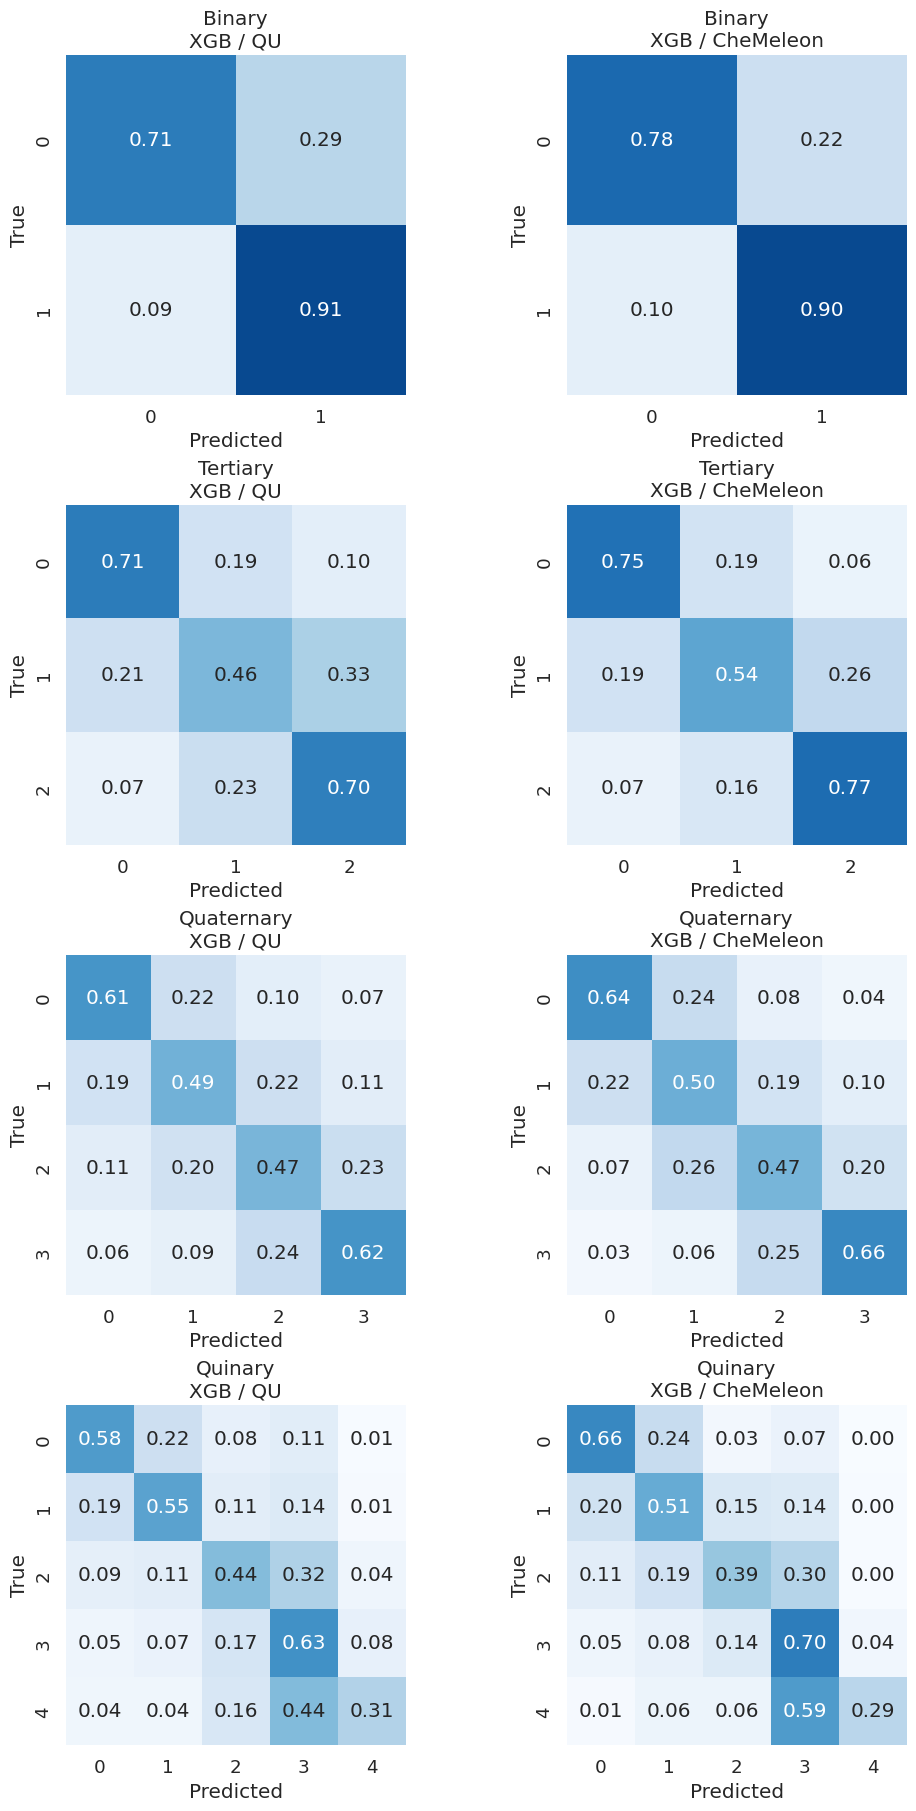

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_xgb_qu_chemeleon_confusion_matrices.png


In [55]:
comparison_embeddings = ("hq_descriptor", "chemeleon")
comparison_model = "xgboost"
fig, axes = plt.subplots(
    len(CLASSIFICATIONS),
    len(comparison_embeddings),
    figsize=(10, 4.5 * len(CLASSIFICATIONS)),
    constrained_layout=True,
    squeeze=False,
)

for row, classification in enumerate(CLASSIFICATIONS):
    for column, embedding in enumerate(comparison_embeddings):
        subset = runs.loc[
            (runs["classification"] == classification)
            & (runs["model"] == comparison_model)
            & (runs["embedding"] == embedding)
        ]
        title = (
            f"{CLASSIFICATION_LABELS[classification]}\n"
            f"{MODEL_LABELS[comparison_model]} / {EMBEDDING_LABELS[embedding]}"
        )
        draw_confusion_matrix(axes[row, column], subset, title)

save_figure(fig, "classification_xgb_qu_chemeleon_confusion_matrices.png");

## 5. ROC curves for one selected run

This supports binary ROC and multiclass one-vs-rest ROC. The first available seed is used.

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.2.2 w

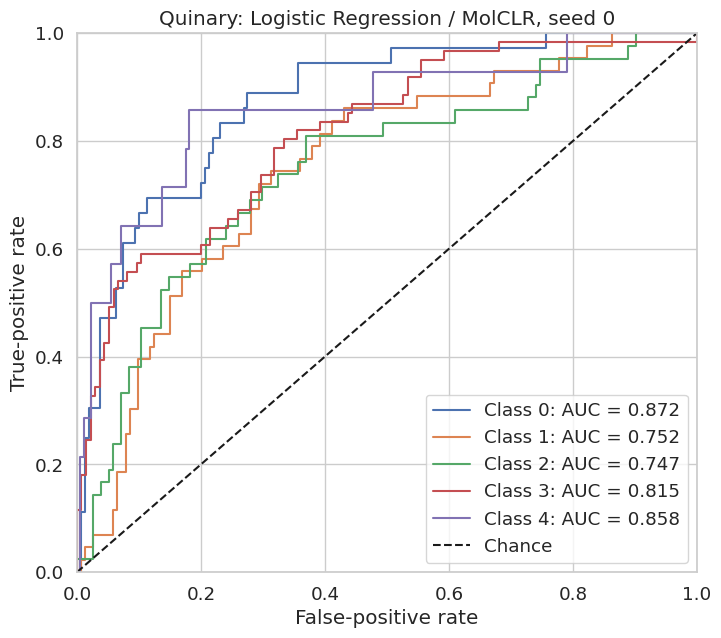

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_quinary_logreg_molclr_roc.png


In [56]:
SELECTED_CLASSIFICATION = "quinary"
SELECTED_MODEL = "logreg"
SELECTED_EMBEDDING = "molclr"

selected = runs.loc[
    (runs["classification"] == SELECTED_CLASSIFICATION)
    & (runs["model"] == SELECTED_MODEL)
    & (runs["embedding"] == SELECTED_EMBEDDING)
].sort_values("seed")
run = selected.iloc[0]

artifact = joblib.load(Path(run["run_dir"]) / "model_and_results.pkl")
model = artifact["best_estimator"]
test_idx = np.asarray(artifact["test_idx"], dtype=int)
y_test = np.asarray(artifact["y_test"])
x_test = np.load(embedding_paths[SELECTED_EMBEDDING], mmap_mode="r")[test_idx]
scores = (
    model.predict_proba(x_test)
    if hasattr(model, "predict_proba")
    else model.decision_function(x_test)
)
classes = np.asarray(model.classes_)

fig, axis = plt.subplots(figsize=(8, 7))
if len(classes) == 2:
    positive_scores = scores[:, 1] if np.ndim(scores) == 2 else scores
    fpr, tpr, _ = roc_curve(y_test, positive_scores, pos_label=classes[1])
    axis.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
else:
    binary_targets = label_binarize(y_test, classes=classes)
    for column, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(binary_targets[:, column], scores[:, column])
        axis.plot(fpr, tpr, label=f"Class {label}: AUC = {auc(fpr, tpr):.3f}")

axis.plot([0, 1], [0, 1], "k--", label="Chance")
axis.set(
    title=(
        f"{CLASSIFICATION_LABELS[SELECTED_CLASSIFICATION]}: "
        f"{MODEL_LABELS[SELECTED_MODEL]} / {EMBEDDING_LABELS[SELECTED_EMBEDDING]}, "
        f"seed {run.seed}"
    ),
    xlabel="False-positive rate",
    ylabel="True-positive rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
axis.legend(loc="lower right")
save_figure(
    fig,
    f"classification_{SELECTED_CLASSIFICATION}_{SELECTED_MODEL}_{SELECTED_EMBEDDING}_roc.png",
);

## 6. Generalisation, runtime, difficult molecules, and hyperparameters

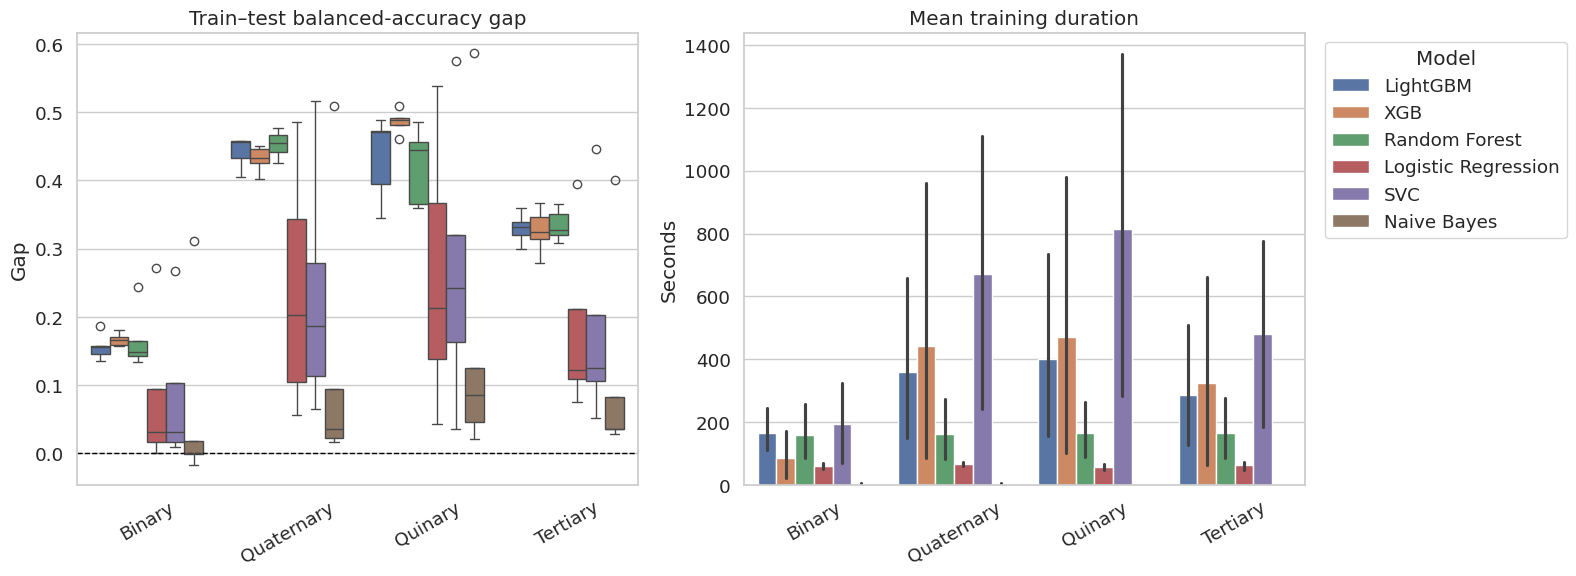

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_generalisation_and_runtime.png


In [57]:
plot_aggregate_results = apply_display_labels(aggregate_results)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=plot_aggregate_results,
    x="classification",
    y="generalisation_gap_mean",
    hue="model",
    ax=axes[0],
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Train–test balanced-accuracy gap", xlabel="", ylabel="Gap")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=plot_aggregate_results,
    x="classification",
    y="duration_seconds_mean",
    hue="model",
    ax=axes[1],
)
axes[1].set(title="Mean training duration", xlabel="", ylabel="Seconds")
axes[1].tick_params(axis="x", rotation=30)
axes[0].get_legend().remove()
axes[1].legend(title="Model", bbox_to_anchor=(1.02, 1))

fig.tight_layout()
save_figure(fig, "classification_generalisation_and_runtime.png");

In [58]:
predictions, difficult_molecules = load_predictions(runs)
if not difficult_molecules.empty:
    display(difficult_molecules.groupby("classification", group_keys=False).head(10))

hyperparameter_frequency = (
    runs.groupby(
        ["classification", "model", "embedding", "best_params"], as_index=False
    )
    .agg(seeds=("seed", "nunique"))
    .sort_values(
        ["classification", "model", "embedding", "seeds"],
        ascending=[True, True, True, False],
    )
)
display(hyperparameter_frequency.head(30))

,classification,row_index,true_class,evaluations,errors,error_rate,SMILES,canonical_SMILES,Source,Exp IS (J)
0,binary,218,0,30,30,1.000000,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2nnc(-c3c([N...,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2nnc(-c3c([N...,APPLETON,4.903325
1,binary,293,0,30,30,1.000000,C=Cc1c([N+](=O)[O-])cc([N+](=O)[O-])cc1[N+](=O...,C=Cc1c([N+](=O)[O-])cc([N+](=O)[O-])cc1[N+](=O...,APPLETON,7.845320
2,binary,751,0,30,30,1.000000,O=[N+](C1=C(C2=C([N+]([O-])=O)NN=C2[N+]([O-])=...,O=[N+]([O-])c1n[nH]c([N+](=O)[O-])c1-c1c([N+](...,QUAYLE,4.500000
3,binary,312,0,60,58,0.966667,n6nc1nonc1c2nonc2c3nonc3nnc4nonc4c5nonc5c7nonc67,N1=Nc2nonc2-c2nonc2-c2nonc2N=Nc2nonc2-c2nonc2-...,MARRS,3.748500
4,binary,382,1,30,29,0.966667,O=N(=O)OCCN(CCON(=O)=O)C(CON(=O)=O)(CON(=O)=O)...,O=[N+]([O-])OCCN(CCO[N+](=O)[O-])C(CO[N+](=O)[...,MARRS,8.000000
5,binary,408,1,30,29,0.966667,O=C(OCC(N(=O)=O)(N(=O)=O)N(=O)=O)N(CCN(CC(N(=O...,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,MARRS,10.000000
6,binary,509,0,30,29,0.966667,N#N=c2c(n1nc(N(=O)=O)c(N)c1N(=O)=O)nnc2n3nc(N(...,[N-]=[N+]=C1C(n2nc([N+](=O)[O-])c(N)c2[N+](=O)...,MARRS,7.595000
7,binary,628,0,30,29,0.966667,Nn1nc(N(=O)=O)c2c1c(N(=O)=O)nn2N,Nn1nc([N+](=O)[O-])c2c1c([N+](=O)[O-])nn2N,MARRS,7.000000
8,binary,630,0,30,29,0.966667,NN/C(N)=C(N(=O)=O)/N(=O)=O,NNC(N)=C([N+](=O)[O-])[N+](=O)[O-],MARRS,6.000000
9,binary,863,1,30,29,0.966667,O=[N+](OCC1=C(CO[N+]([O-])=O)N(CCO[N+]([O-])=O...,O=[N+]([O-])OCCn1nnc(CO[N+](=O)[O-])c1CO[N+](=...,QUAYLE,9.000000


,classification,model,embedding,best_params,seeds
1,binary,bayes,chemeleon,"{""classifier__var_smoothing"": 3.16227766016837...",3
0,binary,bayes,chemeleon,"{""classifier__var_smoothing"": 1e-06}",2
2,binary,bayes,hq_descriptor,"{""classifier__var_smoothing"": 1e-12}",5
3,binary,bayes,maceoff_large,"{""classifier__var_smoothing"": 1e-12}",5
4,binary,bayes,molclr,"{""classifier__var_smoothing"": 1e-12}",5
5,binary,bayes,morgan_fps,"{""classifier__var_smoothing"": 1e-12}",5
6,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
7,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
8,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
9,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1


## 7. Are errors concentrated near the continuous class boundaries?

The class labels are deterministic bins of a noisy continuous measurement. The plots below therefore aggregate **held-out predictions only** into one vote distribution per molecule, preventing molecules present in several test splits or model runs from receiving extra weight.

The first plot shows which labels the models assign across the original continuous IS range. The second asks whether errors fall as a molecule moves farther from its nearest cutoff. Distance is multiplicative: a value of 1.25 means that the measurement is a factor of 1.25 from the nearest boundary. Consistent errors far from every boundary are stronger model-failure or label-review candidates; errors close to a boundary are compatible with experimental repeatability changing the assigned class. Neither pattern can prove a mislabel without replicate measurements.

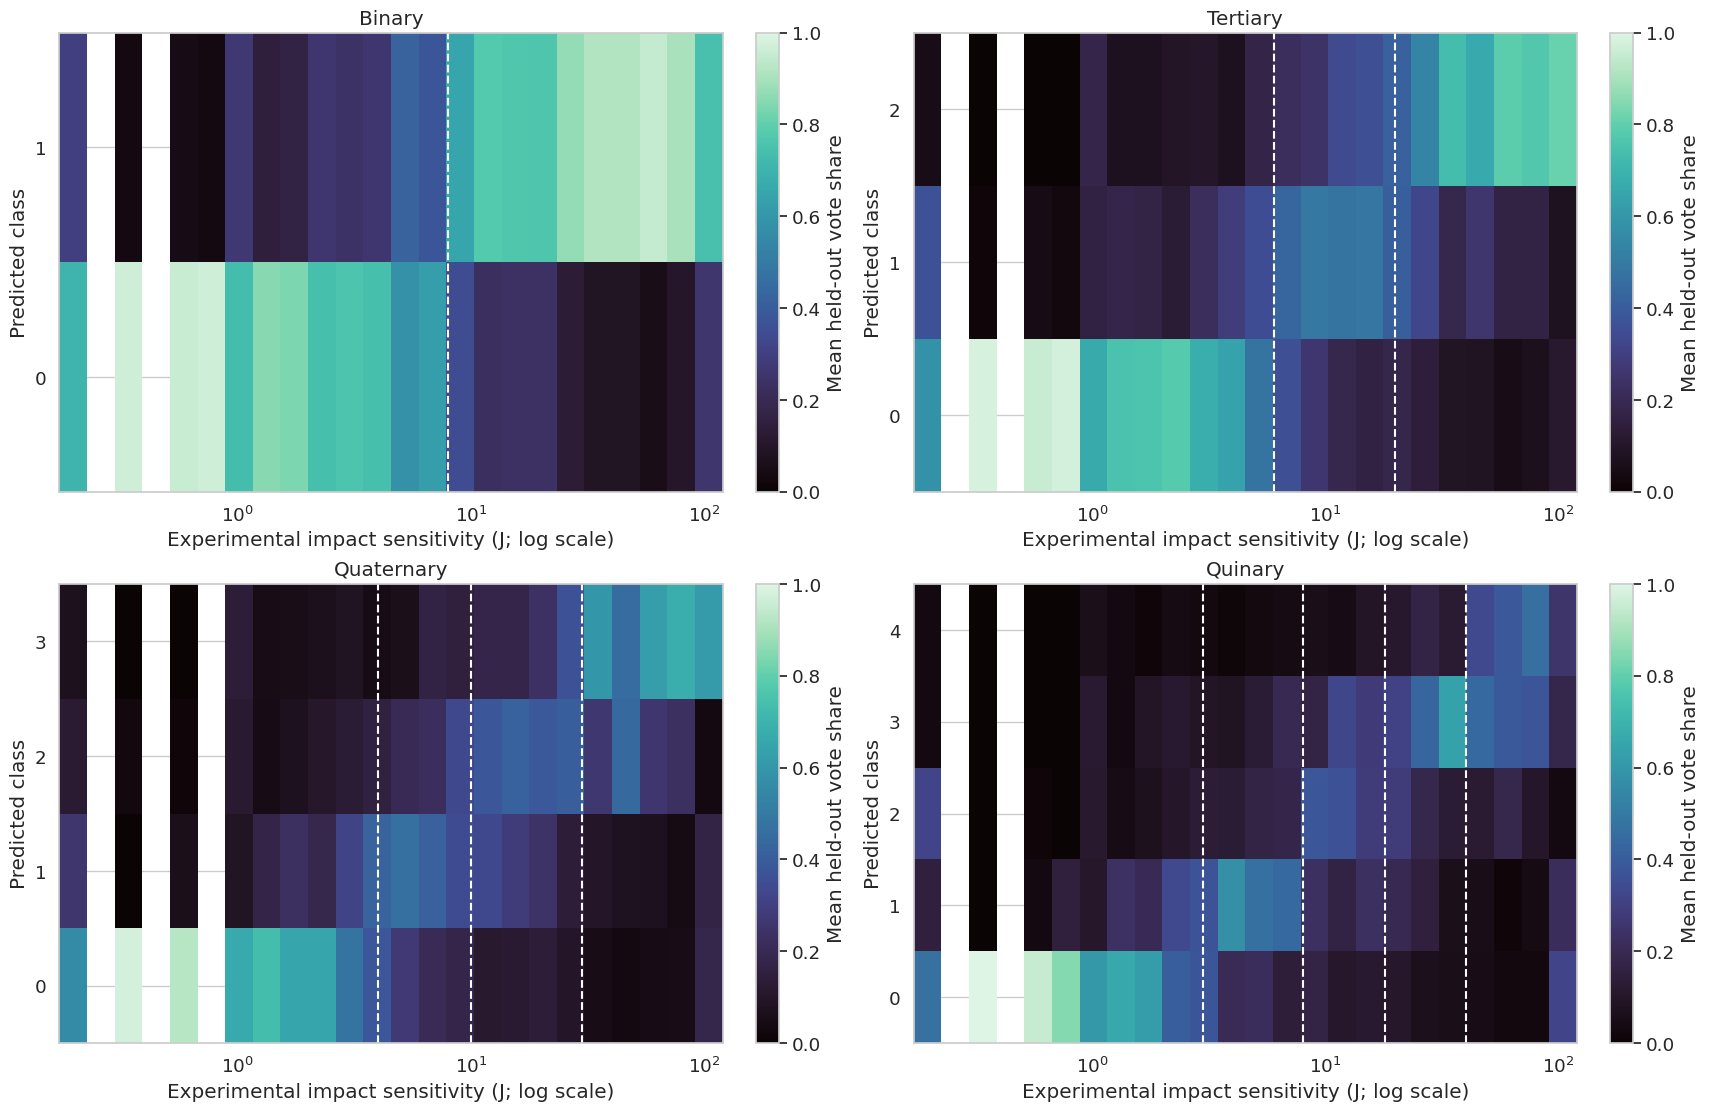

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_predictions_across_continuous_is.png


In [59]:
CLASS_CUTOFFS = {
    "binary": [8],
    "tertiary": [6, 20],
    "quaternary": [4, 10, 30],
    "quinary": [3, 8, 18, 40],
}

if predictions.empty:
    raise ValueError("No held-out predictions are available for boundary analysis")

# One row per molecule and predicted class; absent classes explicitly receive zero votes.
vote_wide = pd.crosstab(
    index=[
        predictions["classification"], predictions["row_index"],
        predictions["true_class"], predictions["Exp IS (J)"],
    ],
    columns=predictions["predicted_class"],
    normalize="index",
).reset_index()
vote_wide.columns.name = None
predicted_columns = sorted(
    column for column in vote_wide.columns if isinstance(column, (int, np.integer))
)
vote_long = vote_wide.melt(
    id_vars=["classification", "row_index", "true_class", "Exp IS (J)"],
    value_vars=predicted_columns,
    var_name="predicted_class",
    value_name="vote_share",
)

positive_is = vote_long.loc[vote_long["Exp IS (J)"] > 0, "Exp IS (J)"]
is_edges = np.geomspace(positive_is.min(), positive_is.max(), 25)
vote_long["is_bin"] = pd.cut(
    vote_long["Exp IS (J)"], bins=is_edges, include_lowest=True, labels=False
)

fig, axes = plt.subplots(2, 2, figsize=(17, 11), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    n_classes = len(CLASS_CUTOFFS[classification]) + 1
    heatmap_data = (
        vote_long.loc[vote_long["classification"] == classification]
        .groupby(["predicted_class", "is_bin"], observed=True)["vote_share"]
        .mean()
        .unstack("is_bin")
        .reindex(index=range(n_classes), columns=range(len(is_edges) - 1))
    )
    mesh = axis.pcolormesh(
        is_edges, np.arange(n_classes + 1) - 0.5, heatmap_data.to_numpy(),
        cmap="mako", vmin=0, vmax=1, shading="flat",
    )
    for cutoff in CLASS_CUTOFFS[classification]:
        axis.axvline(cutoff, color="white", linestyle="--", linewidth=1.5)
    axis.set_xscale("log")
    axis.set_yticks(range(n_classes))
    axis.set(
        title=CLASSIFICATION_LABELS[classification],
        xlabel="Experimental impact sensitivity (J; log scale)",
        ylabel="Predicted class",
    )
    fig.colorbar(mesh, ax=axis, label="Mean held-out vote share")

save_figure(fig, "classification_predictions_across_continuous_is.png");

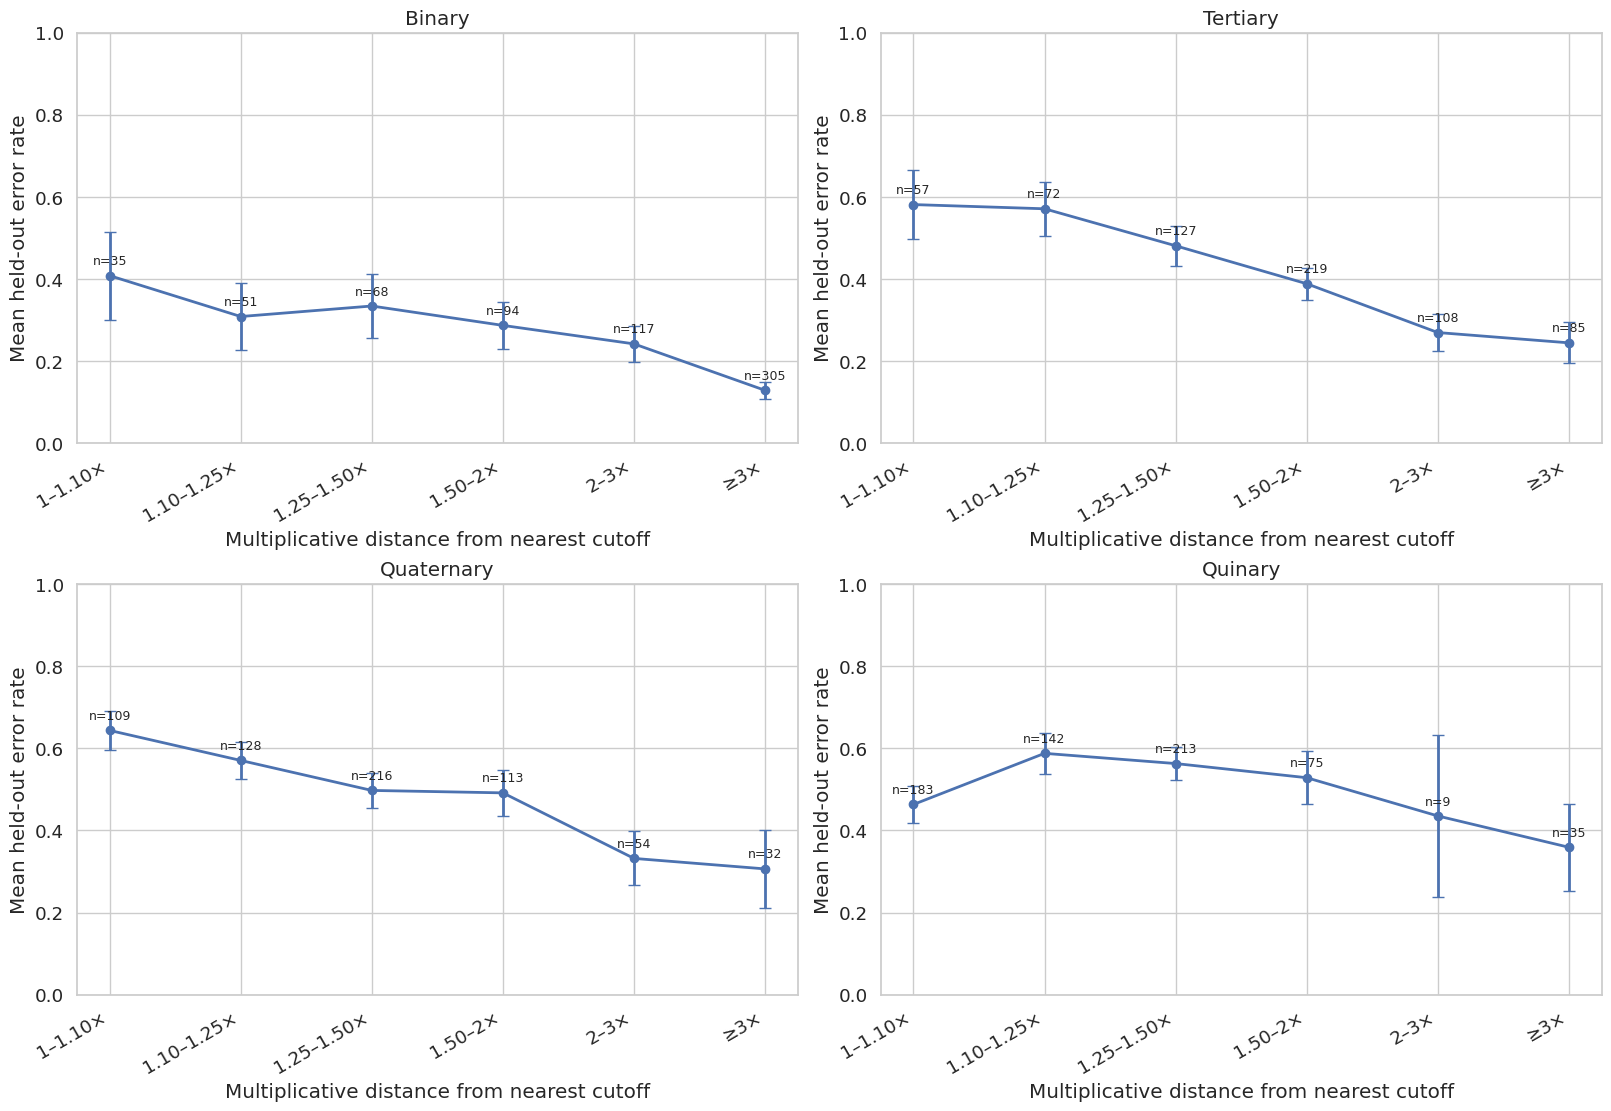

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_error_by_boundary_distance.png


,classification,distance_band,molecules,error_rate,error_sd,ci95
0,binary,1–1.10×,35,0.408333,0.324182,0.107402
1,binary,1.10–1.25×,51,0.308769,0.299906,0.082311
2,binary,1.25–1.50×,68,0.334395,0.324058,0.077024
3,binary,1.50–2×,94,0.287175,0.282829,0.057176
4,binary,2–3×,117,0.242165,0.241937,0.043839
5,binary,≥3×,305,0.129053,0.178662,0.020051
6,quaternary,1–1.10×,109,0.643451,0.257032,0.048254
7,quaternary,1.10–1.25×,128,0.570334,0.265569,0.046007
8,quaternary,1.25–1.50×,216,0.497325,0.311784,0.041580
9,quaternary,1.50–2×,113,0.491396,0.299983,0.055311


In [60]:
# Collapse the vote distribution to per-molecule error and consensus summaries.
molecule_boundary = (
    vote_long.assign(
        correct_vote=lambda frame: frame["vote_share"].where(
            frame["predicted_class"] == frame["true_class"], 0
        )
    )
    .groupby(
        ["classification", "row_index", "true_class", "Exp IS (J)"],
        as_index=False,
    )
    .agg(correct_vote=("correct_vote", "sum"))
)
consensus = vote_long.loc[
    vote_long.groupby(["classification", "row_index"])["vote_share"].idxmax(),
    ["classification", "row_index", "predicted_class", "vote_share"],
].rename(columns={
    "predicted_class": "consensus_class", "vote_share": "consensus_share"
})
molecule_boundary = molecule_boundary.merge(
    consensus, on=["classification", "row_index"], how="left"
)
molecule_boundary["error_rate"] = 1 - molecule_boundary["correct_vote"]
molecule_boundary["boundary_factor"] = molecule_boundary.apply(
    lambda row: float(np.exp(np.min(np.abs(
        np.log(row["Exp IS (J)"]) - np.log(CLASS_CUTOFFS[row["classification"]])
    )))),
    axis=1,
)

distance_edges = [1, 1.10, 1.25, 1.50, 2, 3, np.inf]
distance_labels = ["1–1.10×", "1.10–1.25×", "1.25–1.50×", "1.50–2×", "2–3×", "≥3×"]
molecule_boundary["distance_band"] = pd.cut(
    molecule_boundary["boundary_factor"],
    bins=distance_edges, labels=distance_labels, include_lowest=True, right=False,
)
boundary_error = (
    molecule_boundary.groupby(["classification", "distance_band"], observed=True)
    .agg(
        molecules=("row_index", "nunique"),
        error_rate=("error_rate", "mean"),
        error_sd=("error_rate", "std"),
    )
    .reset_index()
)
boundary_error["ci95"] = (
    1.96 * boundary_error["error_sd"] / np.sqrt(boundary_error["molecules"])
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    subset = (
        boundary_error.loc[boundary_error["classification"] == classification]
        .set_index("distance_band").reindex(distance_labels).reset_index()
    )
    x = np.arange(len(subset))
    axis.errorbar(
        x, subset["error_rate"], yerr=subset["ci95"],
        marker="o", capsize=4, linewidth=2,
    )
    for position, row in subset.iterrows():
        if pd.notna(row["molecules"]):
            axis.annotate(
                f"n={int(row['molecules'])}", (position, row["error_rate"]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9,
            )
    axis.set_xticks(x, distance_labels, rotation=30, ha="right")
    axis.set(
        title=CLASSIFICATION_LABELS[classification],
        xlabel="Multiplicative distance from nearest cutoff",
        ylabel="Mean held-out error rate",
        ylim=(0, 1),
    )

save_figure(fig, "classification_error_by_boundary_distance.png");
display(boundary_error)

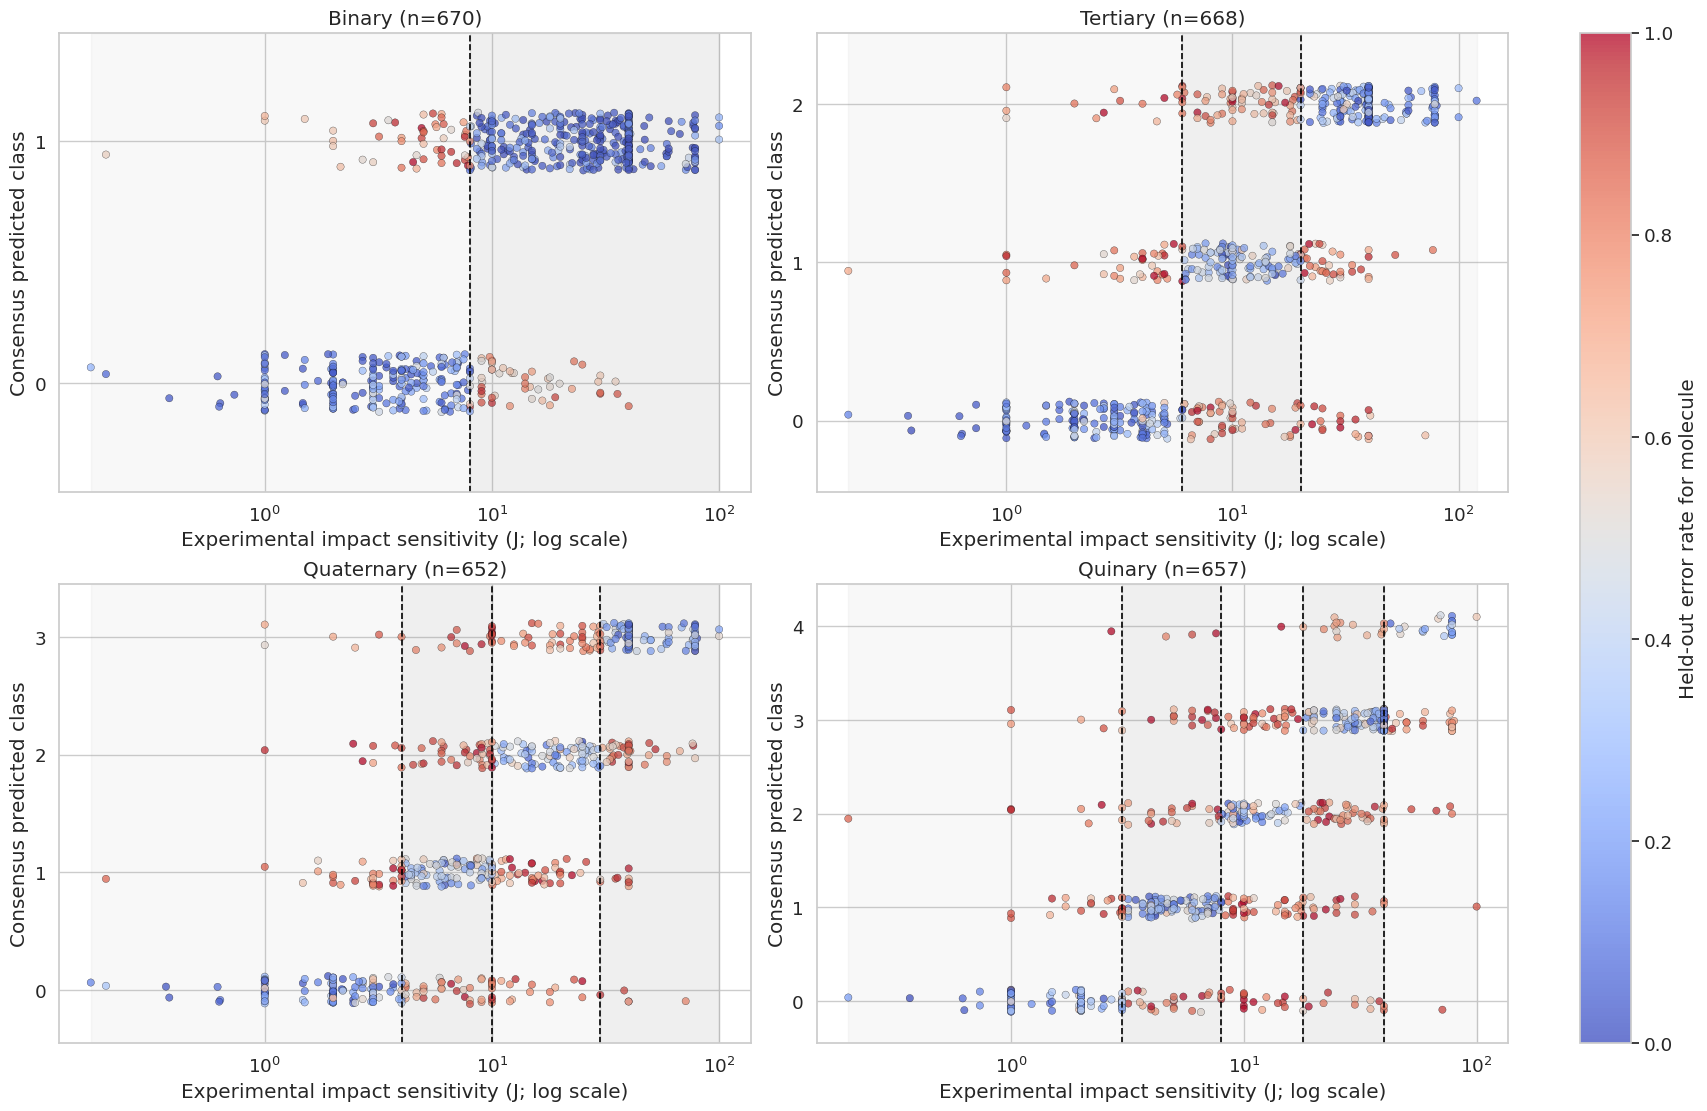

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_individual_molecule_scatter.png


In [61]:
# Individual-molecule view. Vertical jitter only separates overlapping dots;
# the nearest integer remains the molecule's consensus predicted class.
scatter_molecules = molecule_boundary.copy()
scatter_molecules["class_jitter"] = (
    (scatter_molecules["row_index"] * 0.61803398875) % 1 - 0.5
) * 0.24
scatter_molecules["scatter_class"] = (
    scatter_molecules["consensus_class"] + scatter_molecules["class_jitter"]
)

fig, axes = plt.subplots(2, 2, figsize=(17, 11), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    subset = scatter_molecules.loc[
        scatter_molecules["classification"] == classification
    ]
    n_classes = len(CLASS_CUTOFFS[classification]) + 1
    scatter = axis.scatter(
        subset["Exp IS (J)"], subset["scatter_class"],
        c=subset["error_rate"], cmap="coolwarm", vmin=0, vmax=1,
        s=28, alpha=0.75, edgecolors="black", linewidths=0.25,
    )
    for class_index, (left, right) in enumerate(zip(
        [subset["Exp IS (J)"].min()] + CLASS_CUTOFFS[classification],
        CLASS_CUTOFFS[classification] + [subset["Exp IS (J)"].max()],
    )):
        axis.axvspan(left, right, color="grey", alpha=0.05 if class_index % 2 == 0 else 0.12)
    for cutoff in CLASS_CUTOFFS[classification]:
        axis.axvline(cutoff, color="black", linestyle="--", linewidth=1.2)
    axis.set_xscale("log")
    axis.set_yticks(range(n_classes))
    axis.set_ylim(-0.45, n_classes - 0.55)
    axis.set(
        title=f"{CLASSIFICATION_LABELS[classification]} (n={len(subset)})",
        xlabel="Experimental impact sensitivity (J; log scale)",
        ylabel="Consensus predicted class",
    )

fig.colorbar(scatter, ax=axes.ravel().tolist(), label="Held-out error rate for molecule")
save_figure(fig, "classification_individual_molecule_scatter.png");

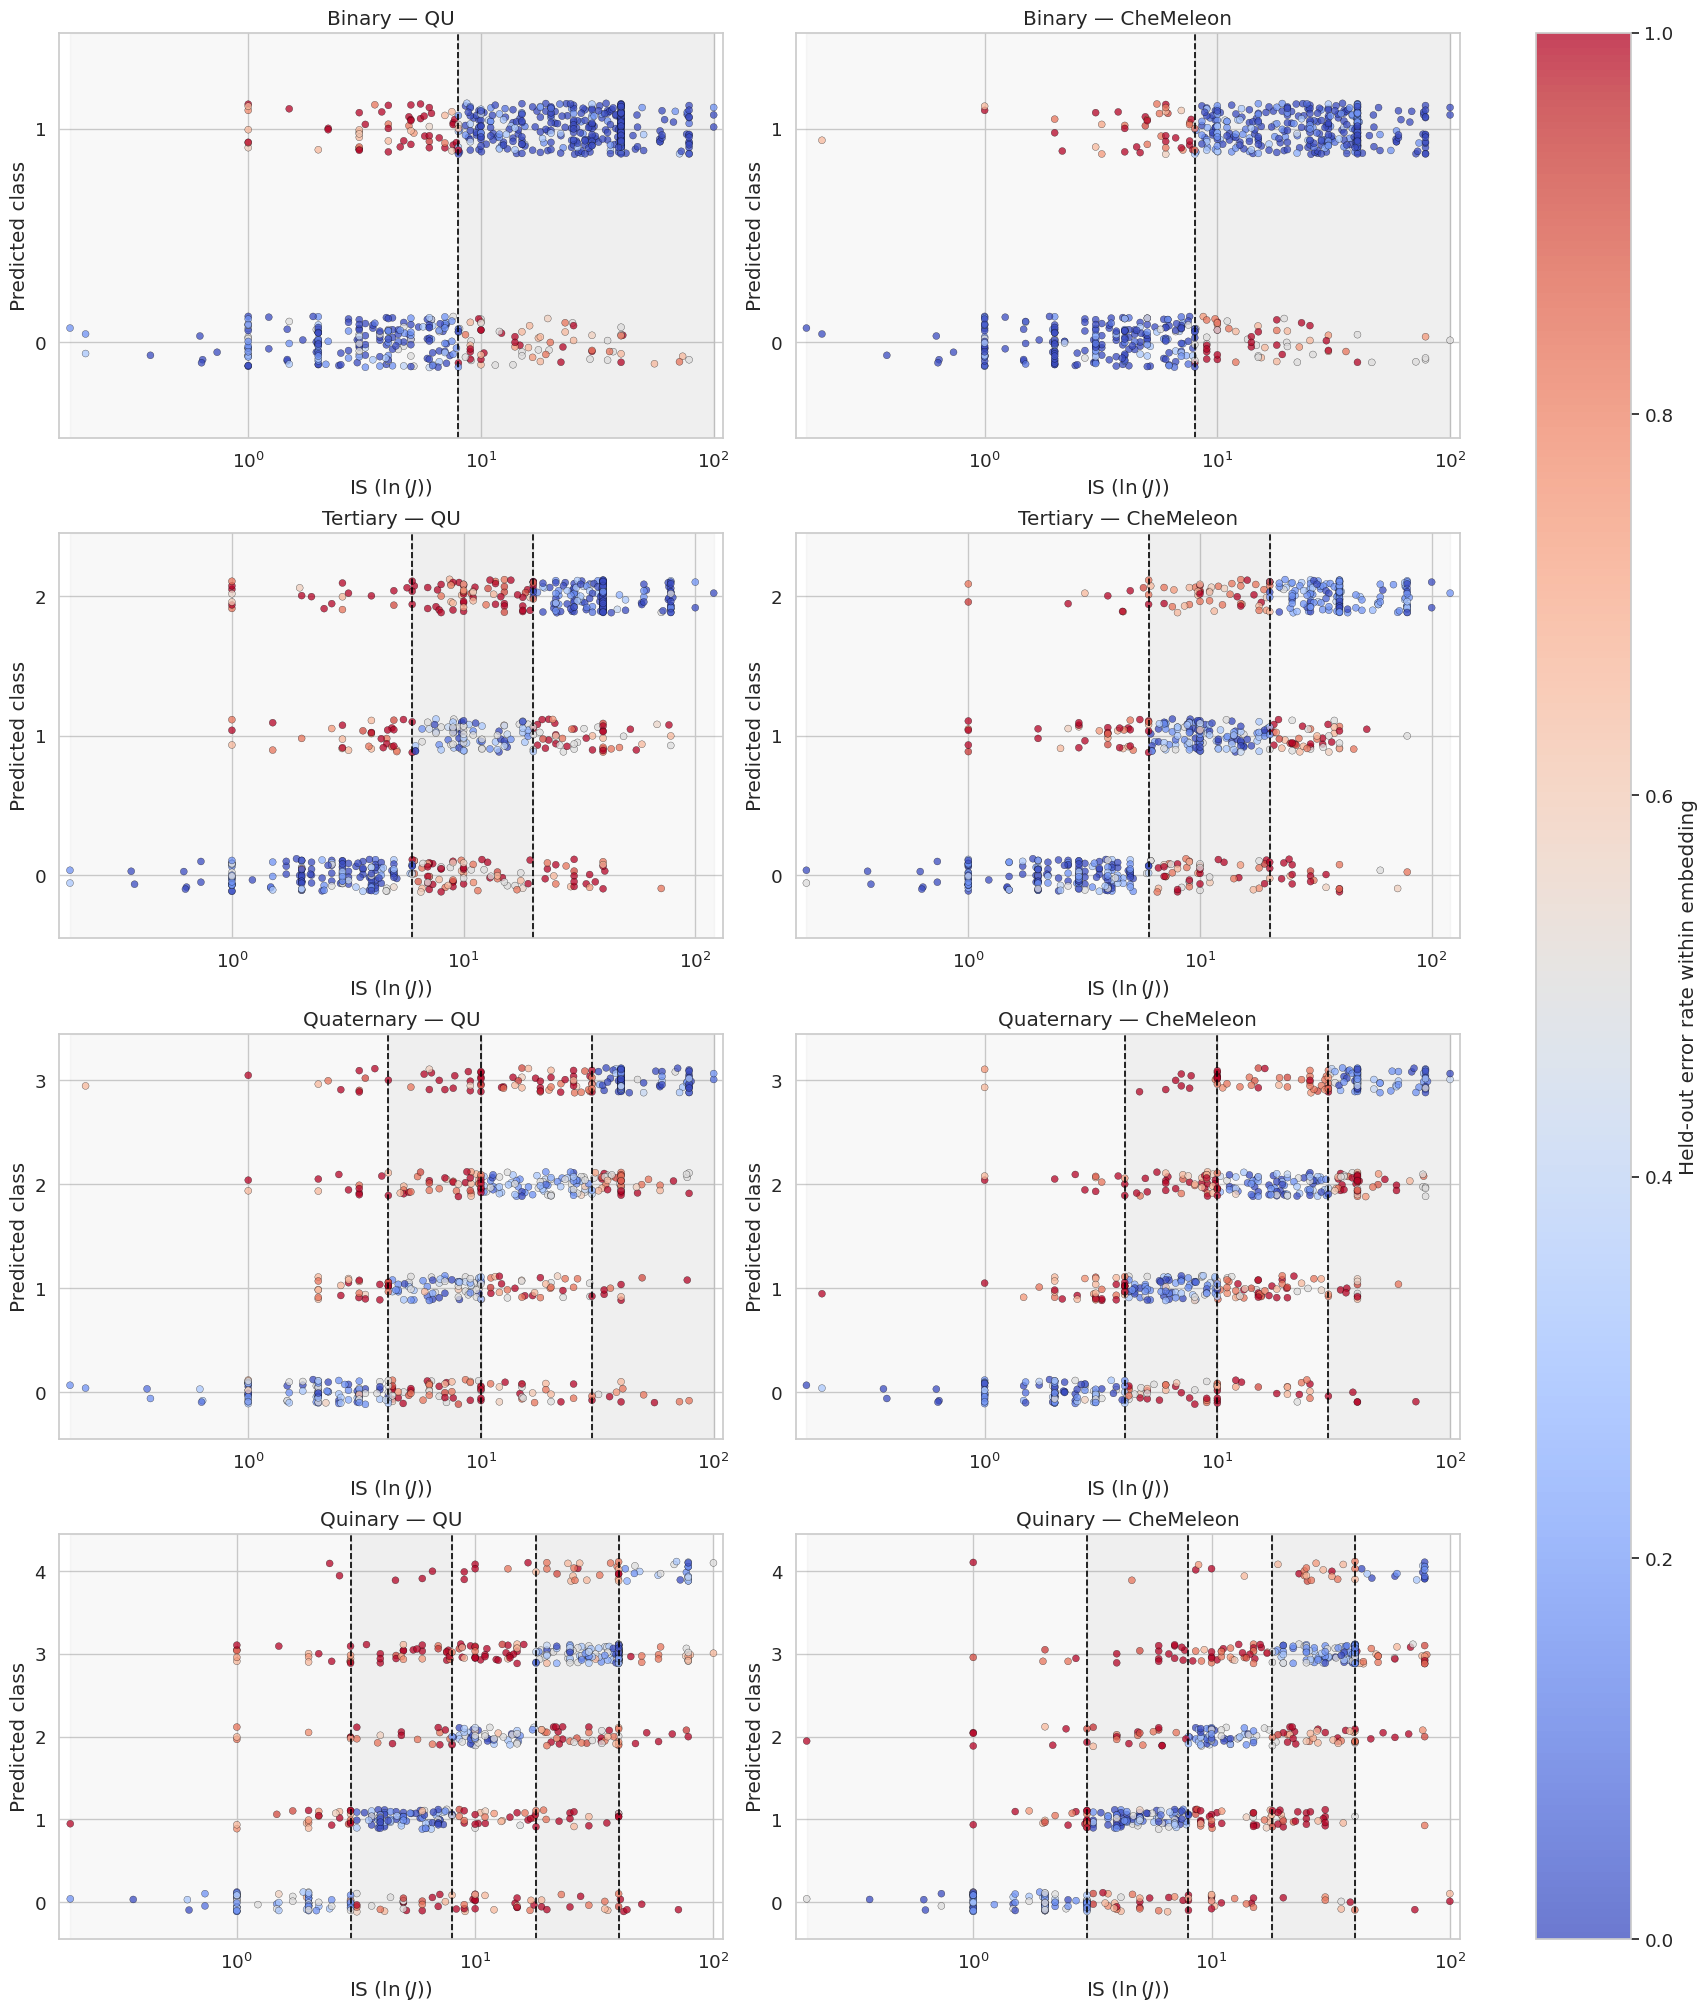

Saved 07_OUTPUTS/20260805/classification_evaluation/figures/classification_individual_scatter_qu_vs_chemeleon.png


,classification,embedding,molecules,mean_error_rate,consensus_accuracy
0,Binary,CheMeleon,670,0.197015,0.825373
1,Binary,QU,670,0.226472,0.767164
2,Quaternary,CheMeleon,652,0.487048,0.487730
3,Quaternary,QU,652,0.523070,0.400307
4,Quinary,CheMeleon,657,0.503150,0.465753
5,Quinary,QU,657,0.540483,0.401826
6,Tertiary,CheMeleon,668,0.368929,0.648204
7,Tertiary,QU,668,0.424214,0.534431


In [70]:
# Matched molecule-level comparison of QU and CheMeleon. Votes are recomputed
# within each embedding, then aggregated across available models and seeds.
COMPARISON_EMBEDDINGS = ["hq_descriptor", "chemeleon"]
comparison_predictions = predictions.loc[
    predictions["embedding"].isin(COMPARISON_EMBEDDINGS)
]
embedding_vote_wide = pd.crosstab(
    index=[
        comparison_predictions["classification"],
        comparison_predictions["embedding"],
        comparison_predictions["row_index"],
        comparison_predictions["true_class"],
        comparison_predictions["Exp IS (J)"],
    ],
    columns=comparison_predictions["predicted_class"],
    normalize="index",
).reset_index()
embedding_vote_wide.columns.name = None
embedding_predicted_columns = sorted(
    column for column in embedding_vote_wide.columns
    if isinstance(column, (int, np.integer))
)
embedding_vote_long = embedding_vote_wide.melt(
    id_vars=[
        "classification", "embedding", "row_index",
        "true_class", "Exp IS (J)",
    ],
    value_vars=embedding_predicted_columns,
    var_name="predicted_class",
    value_name="vote_share",
)
embedding_molecules = (
    embedding_vote_long.assign(
        correct_vote=lambda frame: frame["vote_share"].where(
            frame["predicted_class"] == frame["true_class"], 0
        )
    )
    .groupby(
        ["classification", "embedding", "row_index",
         "true_class", "Exp IS (J)"],
        as_index=False,
    )
    .agg(correct_vote=("correct_vote", "sum"))
)
embedding_consensus = embedding_vote_long.loc[
    embedding_vote_long.groupby(
        ["classification", "embedding", "row_index"]
    )["vote_share"].idxmax(),
    ["classification", "embedding", "row_index",
     "predicted_class", "vote_share"],
].rename(columns={
    "predicted_class": "consensus_class",
    "vote_share": "consensus_share",
})
embedding_molecules = embedding_molecules.merge(
    embedding_consensus,
    on=["classification", "embedding", "row_index"],
    how="left",
)
embedding_molecules["error_rate"] = 1 - embedding_molecules["correct_vote"]
embedding_molecules["scatter_class"] = (
    embedding_molecules["consensus_class"]
    + ((embedding_molecules["row_index"] * 0.61803398875) % 1 - 0.5) * 0.24
)

fig, axes = plt.subplots(
    len(CLASSIFICATIONS), len(COMPARISON_EMBEDDINGS),
    figsize=(17, 20), constrained_layout=True, squeeze=False,
)
for row, classification in enumerate(CLASSIFICATIONS):
    n_classes = len(CLASS_CUTOFFS[classification]) + 1
    classification_values = embedding_molecules.loc[
        embedding_molecules["classification"] == classification, "Exp IS (J)"
    ]
    x_min, x_max = classification_values.min(), classification_values.max()
    for column, embedding in enumerate(COMPARISON_EMBEDDINGS):
        axis = axes[row, column]
        subset = embedding_molecules.loc[
            (embedding_molecules["classification"] == classification)
            & (embedding_molecules["embedding"] == embedding)
        ]
        for class_index, (left, right) in enumerate(zip(
            [x_min] + CLASS_CUTOFFS[classification],
            CLASS_CUTOFFS[classification] + [x_max],
        )):
            axis.axvspan(
                left, right, color="grey",
                alpha=0.05 if class_index % 2 == 0 else 0.12,
            )
        comparison_scatter = axis.scatter(
            subset["Exp IS (J)"], subset["scatter_class"],
            c=subset["error_rate"], cmap="coolwarm", vmin=0, vmax=1,
            s=25, alpha=0.75, edgecolors="black", linewidths=0.25,
        )
        for cutoff in CLASS_CUTOFFS[classification]:
            axis.axvline(cutoff, color="black", linestyle="--", linewidth=1.2)
        axis.set_xscale("log")
        axis.set_xlim(x_min * 0.9, x_max * 1.1)
        axis.set_yticks(range(n_classes))
        axis.set_ylim(-0.45, n_classes - 0.55)
        axis.set(
            title=(
                f"{CLASSIFICATION_LABELS[classification]} — {EMBEDDING_LABELS[embedding]}"
                #f" (mean error={subset['error_rate'].mean():.1%})"
            ),
            xlabel=r"IS ($\ln{(J)}$)",
            ylabel="Predicted class",
        )

fig.colorbar(
    comparison_scatter, ax=axes.ravel().tolist(),
    label="Held-out error rate within embedding",
)
save_figure(fig, "classification_individual_scatter_qu_vs_chemeleon.png");

embedding_comparison_summary = (
    embedding_molecules.groupby(["classification", "embedding"], as_index=False)
    .agg(
        molecules=("row_index", "nunique"),
        mean_error_rate=("error_rate", "mean"),
        consensus_accuracy=(
            "correct_vote", lambda values: np.mean(values > 0.5)
        ),
    )
)
display(apply_display_labels(embedding_comparison_summary))

In [63]:
# Sensitivity analysis: how many labels could cross a cutoff under an assumed
# symmetric multiplicative repeatability range? These are ambiguity flags, not proven errors.
repeatability_factors = [1.10, 1.25, 1.50, 2.00]
ambiguity_sensitivity = pd.DataFrame([
    {
        "classification": classification,
        "repeatability_factor": factor,
        "potentially_boundary_ambiguous": (group["boundary_factor"] <= factor).mean(),
        "error_rate_inside_band": group.loc[
            group["boundary_factor"] <= factor, "error_rate"
        ].mean(),
        "error_rate_outside_band": group.loc[
            group["boundary_factor"] > factor, "error_rate"
        ].mean(),
    }
    for classification, group in molecule_boundary.groupby("classification")
    for factor in repeatability_factors
])

review_candidates = (
    molecule_boundary.loc[
        (molecule_boundary["boundary_factor"] >= 1.5)
        & (molecule_boundary["error_rate"] >= 0.75)
        & (molecule_boundary["consensus_class"] != molecule_boundary["true_class"])
    ]
    .merge(
        classification_df.reset_index(names="row_index")[
            ["row_index", "canonical_SMILES", "Source"]
        ],
        on="row_index", how="left",
    )
    .sort_values(["error_rate", "boundary_factor"], ascending=False)
)
display(ambiguity_sensitivity.style.format({
    "potentially_boundary_ambiguous": "{:.1%}",
    "error_rate_inside_band": "{:.1%}",
    "error_rate_outside_band": "{:.1%}",
}))
display(review_candidates.head(30))

,classification,repeatability_factor,potentially_boundary_ambiguous,error_rate_inside_band,error_rate_outside_band
0,binary,1.100000,5.2%,40.8%,21.0%
1,binary,1.250000,12.8%,34.9%,20.1%
2,binary,1.500000,23.0%,34.3%,18.4%
3,binary,2.000000,37.2%,32.2%,16.0%
4,quaternary,1.100000,16.7%,64.3%,48.6%
5,quaternary,1.250000,37.1%,60.5%,45.7%
6,quaternary,1.500000,70.1%,55.4%,41.3%
7,quaternary,2.000000,89.0%,53.6%,31.5%
8,quinary,1.100000,27.9%,46.3%,54.7%
9,quinary,1.250000,49.8%,52.0%,52.8%


,classification,row_index,true_class,Exp IS (J),correct_vote,consensus_class,consensus_share,error_rate,boundary_factor,distance_band,canonical_SMILES,Source
90,tertiary,15,0,2.696829,0.000000,2,0.650000,1.000000,2.224835,2–3×,O=[N+]([O-])c1cc([N+](=O)[O-])c(-n2nnc3ccccc32...,APPLETON
16,binary,751,0,4.500000,0.000000,1,1.000000,1.000000,1.777778,1.50–2×,O=[N+]([O-])c1n[nH]c([N+](=O)[O-])c1-c1c([N+](...,QUAYLE
29,quaternary,133,2,16.671305,0.000000,1,0.966667,1.000000,1.667131,1.50–2×,O=C(CCC(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,APPLETON
102,tertiary,422,1,10.000000,0.000000,2,0.983333,1.000000,1.666667,1.50–2×,Nc1n[nH]nc1-c1nnn[nH]1,MARRS
107,tertiary,467,1,10.000000,0.000000,2,0.866667,1.000000,1.666667,1.50–2×,Nc1nnnn1O,MARRS
116,tertiary,763,1,10.000000,0.000000,2,0.966667,1.000000,1.666667,1.50–2×,NN/C(N)=C(/c1nnn[nH]1)[N+](=O)[O-],QUAYLE
23,quaternary,16,0,2.451662,0.000000,2,0.666667,1.000000,1.631546,1.50–2×,O=[N+]([O-])c1cc([N+](=O)[O-])c(-n2ccnn2)c([N+...,APPLETON
0,binary,218,0,4.903325,0.000000,1,1.000000,1.000000,1.631546,1.50–2×,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2nnc(-c3c([N...,APPLETON
24,quaternary,44,2,15.445474,0.000000,1,0.700000,1.000000,1.544547,1.50–2×,CCOC(=O)C12N([N+](=O)[O-])C(=O)N([N+](=O)[O-])...,APPLETON
42,quaternary,506,1,6.615000,0.000000,0,0.733333,1.000000,1.511716,1.50–2×,[N-]=[N+]=N/C(=N\O)c1noc(/C(N=[N+]=[N-])=N\O)n1,MARRS


## 8. Export evaluation tables

In [64]:
export_tables(
    EXPORT_DIR,
    runs,
    aggregate_results,
    missing_runs,
    rejected_summaries,
    predictions,
    difficult_molecules,
    class_metrics,
)
class_metric_summary.to_csv(
    EXPORT_DIR / "classification_per_class_aggregate.csv", index=False
)
hyperparameter_frequency.to_csv(
    EXPORT_DIR / "classification_hyperparameters.csv", index=False
)
boundary_error.to_csv(
    EXPORT_DIR / "classification_boundary_error.csv", index=False
)
ambiguity_sensitivity.to_csv(
    EXPORT_DIR / "classification_boundary_ambiguity_sensitivity.csv", index=False
)
review_candidates.to_csv(
    EXPORT_DIR / "classification_far_boundary_review_candidates.csv", index=False
)
embedding_comparison_summary.to_csv(
    EXPORT_DIR / "classification_qu_vs_chemeleon_summary.csv", index=False
)
print(f"Exported evaluation tables to {EXPORT_DIR}")

Exported evaluation tables to /home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20260805/classification_evaluation
